# Modelos de riesgo de mercado

Cuánto se puede perder, con qué probabilidad, y —sobre todo— si el modelo que lo
predice acierta.

Convención de signos: todas las medidas de riesgo se devuelven como **pérdida
positiva**. Un VaR al 99 % de `0.031` significa que se espera perder más del 3,1 %
sólo el 1 % de los días.

Como en el primer notebook, si no hay acceso a Yahoo Finance se trabaja con datos
simulados y se avisa por pantalla.

In [1]:
import warnings

import numpy as np
import pandas as pd
from scipy import stats

from icm import graficos
from icm.cartera import contraste_jarque_bera, curtosis, asimetria
from icm.datos import cargar_precios, matriz_covarianzas, rendimientos, rendimientos_cartera
from icm.riesgo import (
    ajustar_copula_t,
    ajustar_garch,
    backtest_var,
    bootstrap_historico,
    comparar_copulas,
    comparar_modelos_volatilidad,
    dependencia_cola_empirica,
    es_montecarlo,
    resumen_simulacion,
    serie_caidas,
    simular_cartera,
    tabla_caidas,
    tabla_medidas,
    var_montecarlo,
    volatilidad_ewma,
    volatilidad_movil,
)

graficos.aplicar_estilo()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

In [2]:
TICKERS = ["AAPL", "MSFT", "JNJ", "XOM", "JPM"]
VALOR_CARTERA = 1_000_000

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    precios = cargar_precios(TICKERS, "2015-01-01", "2024-12-31", respaldo_simulado=True)

DATOS_SIMULADOS = any("SIMULADOS" in str(a.message) for a in avisos)
if DATOS_SIMULADOS:
    print("!! Sin acceso a Yahoo Finance: se trabaja con DATOS SIMULADOS.\n")
else:
    print(f"Datos reales de Yahoo Finance: {len(precios)} sesiones.\n")

rend = rendimientos(precios, "log")
pesos = pd.Series(1.0 / len(TICKERS), index=rend.columns)
cartera = rendimientos_cartera(rend, pesos)
print(f"Cartera equiponderada de {len(TICKERS)} activos, {len(cartera)} sesiones.")

Datos reales de Yahoo Finance: 2515 sesiones.

Cartera equiponderada de 5 activos, 2514 sesiones.


## 1. La pregunta previa: ¿son normales los rendimientos?

Todo el VaR paramétrico clásico descansa sobre la normalidad. Si los datos no son
normales, el modelo no es conservador: es directamente incorrecto, y lo es
precisamente en la cola, que es donde importa.

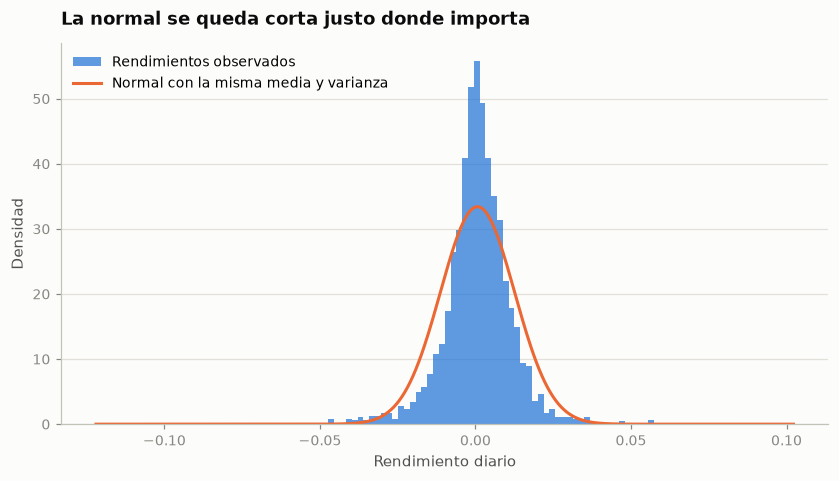

Asimetría:          -0.482   (0 si fuese normal)
Exceso de curtosis: +13.663   (0 si fuese normal)
Jarque-Bera p-valor: 0.00e+00  -> SE RECHAZA la normalidad


In [3]:
import matplotlib.pyplot as plt

figura, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(cartera, bins=120, density=True, color=graficos.PALETA[0], alpha=0.75,
        linewidth=0, label="Rendimientos observados")

rejilla = np.linspace(cartera.min(), cartera.max(), 500)
ax.plot(rejilla, stats.norm.pdf(rejilla, cartera.mean(), cartera.std(ddof=1)),
        color=graficos.PALETA[1], linewidth=2, label="Normal con la misma media y varianza")

ax.set_xlabel("Rendimiento diario")
ax.set_ylabel("Densidad")
ax.set_title("La normal se queda corta justo donde importa")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

prueba = contraste_jarque_bera(cartera)
print(f"Asimetría:          {asimetria(cartera):+.3f}   (0 si fuese normal)")
print(f"Exceso de curtosis: {curtosis(cartera):+.3f}   (0 si fuese normal)")
print(f"Jarque-Bera p-valor: {prueba['p_valor']:.2e}  -> "
      f"{'no se rechaza' if prueba['normal_al_5pct'] else 'SE RECHAZA'} la normalidad")

## 2. Cuatro formas de calcular el mismo número

- **Histórico**: el cuantil empírico. No supone nada, pero no sabe nada de pérdidas
  mayores que la peor observada.
- **Paramétrico normal**: fórmula cerrada. Rápido y, con colas gruesas, optimista.
- **Paramétrico t**: mismo enfoque con colas gruesas ajustadas por verosimilitud.
- **Cornish-Fisher**: corrige el cuantil normal con la asimetría y la curtosis
  observadas. Un término medio barato.

El Expected Shortfall (ES) es la pérdida media *dentro* de la cola. A diferencia
del VaR, es una medida coherente —diversificar nunca puede empeorarlo— y es la que
Basilea III adoptó en sustitución del VaR.

In [4]:
medidas = tabla_medidas(cartera, niveles=(0.95, 0.99), valor_cartera=VALOR_CARTERA)
medidas.round(5)

/home/user/ICM/src/icm/riesgo/var.py:352: UserWarning: Cornish-Fisher fuera de su dominio de validez (asimetria -0.48, exceso de curtosis 13.66): la expansion deja de ser monotona entre z = -1.64 y z = 0.00, que es el tramo que se esta evaluando, y el valor devuelto no es un cuantil fiable. Use el metodo historico o la t de Student con colas tan gruesas.
  return var_cornish_fisher(rendimientos, nivel)
/home/user/ICM/src/icm/riesgo/var.py:369: UserWarning: Cornish-Fisher fuera de su dominio de validez (asimetria -0.48, exceso de curtosis 13.66): la expansion deja de ser monotona entre z = -4.06 y z = 0.00, que es el tramo que se esta evaluando, y el valor devuelto no es un cuantil fiable. Use el metodo historico o la t de Student con colas tan gruesas.
  return es_cornish_fisher(rendimientos, nivel)
/home/user/ICM/src/icm/riesgo/var.py:352: UserWarning: Cornish-Fisher fuera de su dominio de validez (asimetria -0.48, exceso de curtosis 13.66): la expansion deja de ser monotona entre z =

var      es  var_monetario  es_monetario
metodo             nivel                                             
historico          0.95   0.0171  0.0287     17145.7126    28668.0119
                   0.99   0.0343  0.0493     34275.0558    49349.4184
parametrico_normal 0.95   0.0190  0.0240     18983.6658    23973.3080
                   0.99   0.0271  0.0312     27121.3653    31167.7568
parametrico_t      0.95   0.0160  0.0273     15970.8225    27271.1954
                   0.99   0.0321  0.0508     32105.4549    50785.3218
cornish_fisher     0.95   0.0173  0.0504     17274.5662    50411.7109
                   0.99   0.0684  0.1150     68449.9204   114997.4373

Si arriba ha saltado un aviso sobre Cornish-Fisher, conviene pararse. La
expansión es **asintótica**: sólo vale para asimetría y curtosis moderadas. Con
colas muy gruesas el polinomio deja de ser creciente, y una función de cuantiles
que no crece no es una función de cuantiles: el número puede dispararse a
decenas de sigmas. La librería lo detecta y avisa, pero devuelve el valor, así
que hay que leerlo con esa reserva.

```python
from icm.riesgo import dominio_valido_cornish_fisher
dominio_valido_cornish_fisher(asimetria(cartera), curtosis(cartera))
```

In [5]:
from icm.riesgo import dominio_valido_cornish_fisher

valido = dominio_valido_cornish_fisher(asimetria(cartera), curtosis(cartera))
print(f"¿Cornish-Fisher es fiable con estos momentos? {'sí' if valido else 'NO'}")
if not valido:
    print("  Su cifra de arriba no es un cuantil: quédate con el histórico o la t.")

¿Cornish-Fisher es fiable con estos momentos? NO
  Su cifra de arriba no es un cuantil: quédate con el histórico o la t.


In [6]:
al_99 = medidas.xs(0.99, level="nivel")
diferencia = al_99.loc["historico", "var"] / al_99.loc["parametrico_normal", "var"] - 1
print(f"El VaR histórico al 99 % es un {diferencia:+.1%} respecto al paramétrico normal.")
print(f"En euros, sobre una cartera de {VALOR_CARTERA:,.0f}: "
      f"{al_99.loc['historico', 'var_monetario']:,.0f} frente a "
      f"{al_99.loc['parametrico_normal', 'var_monetario']:,.0f}.")

El VaR histórico al 99 % es un +26.4% respecto al paramétrico normal.
En euros, sobre una cartera de 1,000,000: 34,275 frente a 27,121.


## 3. La volatilidad no es constante

Los mercados alternan rachas tranquilas y turbulentas. Un VaR que use la
volatilidad media de los últimos años reacciona tarde y mal.

Tres estimadores, de menos a más sofisticado:

- **Media móvil**: fácil de explicar, pero cuando un día extremo sale de la ventana
  la volatilidad cae de golpe sin que haya pasado nada en el mercado.
- **EWMA** (RiskMetrics): los días pesan `(1-λ)·λ^k`, así que la influencia se
  desvanece suavemente en lugar de desaparecer.
- **GARCH**: modeliza explícitamente la dinámica de la varianza y permite prever.

Los tres se dibujan **desplazados un periodo**: el valor de cada fecha usa solo
información anterior a ella, que es la única forma de compararlos entre sí y de
usarlos para dimensionar una posición. La media móvil sin desplazar —su modo por
defecto— incluye el rendimiento del propio día, y eso no es una estimación sino
el resultado: metiendo un movimiento del 50 % en una sola sesión, la ventana de
21 días se multiplica por 11,2 *en esa misma fecha* mientras que la EWMA ni se
inmuta.


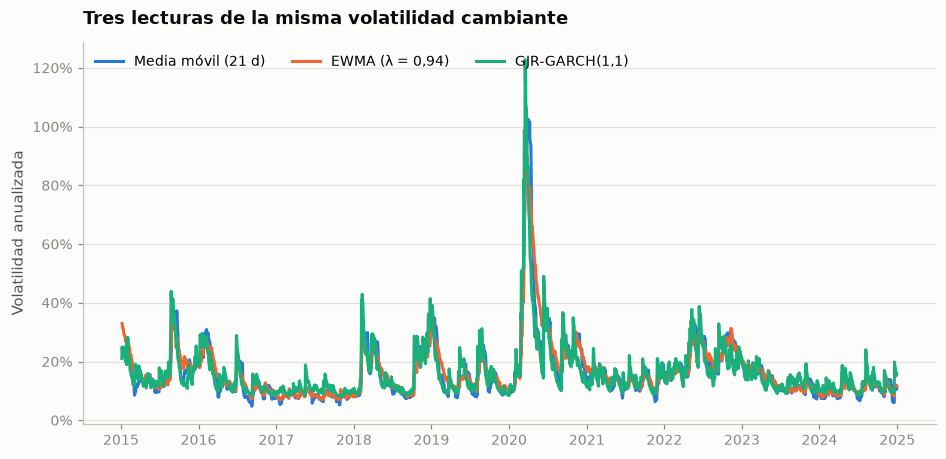

In [7]:
ajuste = ajustar_garch(cartera, "gjr", distribucion="t")

figura, ax = graficos.series_temporales(
    {
        "Media móvil (21 d)": volatilidad_movil(cartera, 21, anualizar=True, prevision=True),
        "EWMA (λ = 0,94)": volatilidad_ewma(cartera, anualizar=True),
        "GJR-GARCH(1,1)": ajuste.volatilidad_condicional(anualizar=True),
    },
    etiqueta_y="Volatilidad anualizada",
    porcentaje=True,
)
ax.set_title("Tres lecturas de la misma volatilidad cambiante");

In [8]:
print(f"Persistencia estimada: {ajuste.persistencia:.3f}")
print("Cuanto más cerca de 1, más tardan en disiparse los choques de volatilidad.\n")
comparar_modelos_volatilidad(cartera, distribucion="t").round(3)

Persistencia estimada: 0.975
Cuanto más cerca de 1, más tardan en disiparse los choques de volatilidad.



,log_verosimilitud,aic,bic,n_parametros,persistencia
gjr,-3342.328,6696.657,6731.635,6.0,0.975
garch,-3370.669,6751.339,6780.487,5.0,0.981
egarch,-3371.815,6753.631,6782.779,5.0,0.976


El GJR añade un término que deja que las caídas eleven más la volatilidad que las
subidas: es el efecto apalancamiento, muy marcado en renta variable. Si mejora el
BIC frente al GARCH simétrico, esa asimetría está en los datos.

## 4. Lo que el inversor percibe: las caídas

La volatilidad es una medida simétrica y abstracta. Lo que de verdad duele es
cuánto se ha llegado a perder desde el último máximo y cuánto se ha tardado en
recuperarlo.

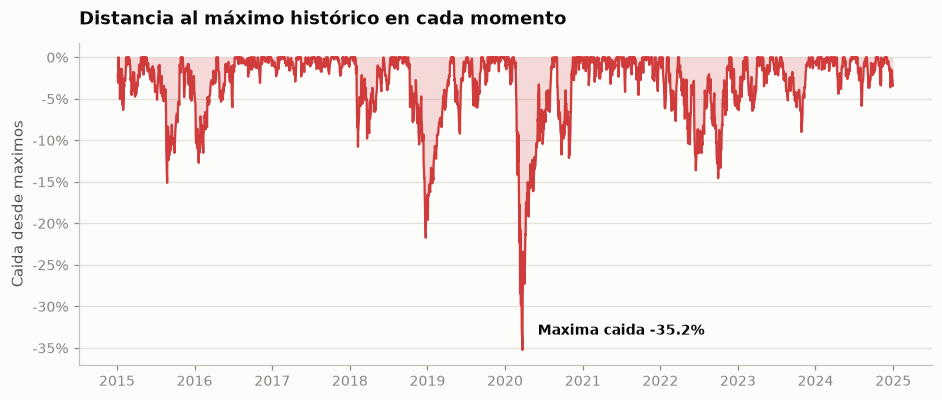

In [9]:
figura, ax = graficos.caidas(serie_caidas(cartera))
ax.set_title("Distancia al máximo histórico en cada momento");

In [10]:
peores = tabla_caidas(cartera, n=5)
peores.assign(caida=lambda t: (t["caida"] * 100).round(1))

,pico,suelo,recuperacion,caida,periodos_hasta_suelo,periodos_recuperacion
0,2020-02-12,2020-03-23,2020-08-12,-35.2,27,99.0
1,2018-10-03,2018-12-24,2019-04-23,-21.7,56,81.0
2,2015-05-19,2015-08-25,2015-10-29,-15.1,68,46.0
3,2022-03-30,2022-09-30,2022-11-23,-14.6,127,38.0
4,2015-11-06,2016-01-21,2016-04-14,-12.7,50,58.0


## 5. Simulación: de una cifra a una distribución

El VaR resume el riesgo en un número. La simulación da la distribución completa, y
con ella se pueden responder preguntas que un cuantil no responde: qué
probabilidad hay de perder más de un 10 % en un mes.

Dos enfoques complementarios:

- **Monte Carlo** con t multivariante: supone una forma para la distribución, pero
  permite extrapolar más allá de lo observado.
- **Bootstrap por bloques**: remuestrea tramos consecutivos de la historia real, de
  modo que conserva el agrupamiento de volatilidad sin suponer nada.

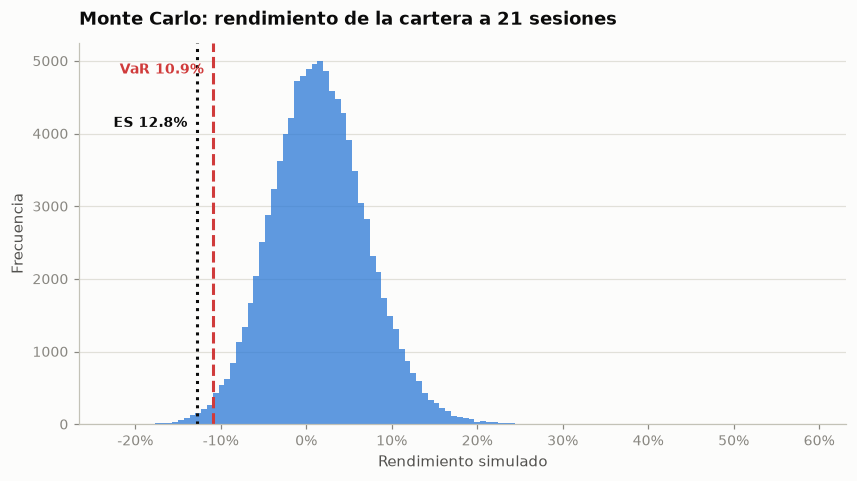

In [11]:
HORIZONTE = 21   # un mes bursátil

mu_diaria = rend.mean()
cov_diaria = matriz_covarianzas(rend)

montecarlo = simular_cartera(
    mu_diaria, cov_diaria, pesos, n_simulaciones=100_000,
    horizonte=HORIZONTE, distribucion="t", grados_libertad=5.0, semilla=42,
)
figura, ax = graficos.distribucion_simulada(
    montecarlo, var=var_montecarlo(montecarlo, 0.99), es=es_montecarlo(montecarlo, 0.99)
)
ax.set_title(f"Monte Carlo: rendimiento de la cartera a {HORIZONTE} sesiones");

In [12]:
bloques = bootstrap_historico(
    rend, pesos, n_simulaciones=100_000, horizonte=HORIZONTE, tamano_bloque=5, semilla=42
)
comparacion_simulacion = pd.DataFrame(
    {
        "Monte Carlo (t)": resumen_simulacion(montecarlo, valor_cartera=VALOR_CARTERA),
        "Bootstrap por bloques": resumen_simulacion(bloques, valor_cartera=VALOR_CARTERA),
    }
)
comparacion_simulacion.loc[
    ["media", "desviacion", "minimo", "prob_perdida", "var_99%", "es_99%",
     "prob_perder_mas_10%", "var_99%_monetario"]
].round(4)

,Monte Carlo (t),Bootstrap por bloques
media,0.0155,0.0151
desviacion,0.0558,0.0484
minimo,-0.2249,-0.2750
prob_perdida,0.3991,0.3506
var_99%,0.1089,0.1172
es_99%,0.1282,0.1469
prob_perder_mas_10%,0.0160,0.0171
var_99%_monetario,108864.3894,117193.6228


## 6. El error que costó caro en 2008: ignorar la dependencia de cola

La matriz de correlación resume la dependencia **media**. No dice nada de lo que
pasa en los extremos, y es ahí donde se decide si una cartera aguanta.

La cópula separa el problema en dos: por un lado el comportamiento individual de
cada activo, por otro la estructura de dependencia. Y la elección de cópula tiene
una consecuencia que no es un detalle técnico:

- La **cópula gaussiana** tiene dependencia de cola **cero**. Por mucha correlación
  que se le ponga, la probabilidad de que dos activos sufran su peor día a la vez
  tiende a cero.
- La **cópula t** sí la tiene, gobernada por sus grados de libertad.

In [13]:
copula_t = ajustar_copula_t(rend)
print(f"Grados de libertad estimados: {copula_t.grados_libertad:.2f}")
print(f"Dependencia de cola implícita (cópula t):        {copula_t.dependencia_cola():.3f}")
print(f"Dependencia de cola implícita (cópula gaussiana): 0.000\n")
print("Frecuencia observada con que dos activos entran juntos en su peor 5 %:")
dependencia_cola_empirica(rend, cuantil=0.05).round(3)

Grados de libertad estimados: 5.37
Dependencia de cola implícita (cópula t):        0.133
Dependencia de cola implícita (cópula gaussiana): 0.000

Frecuencia observada con que dos activos entran juntos en su peor 5 %:


,AAPL,MSFT,JNJ,XOM,JPM
AAPL,1.000,0.504,0.256,0.272,0.304
MSFT,0.504,1.000,0.336,0.256,0.344
JNJ,0.256,0.336,1.000,0.208,0.288
XOM,0.272,0.256,0.208,1.000,0.360
JPM,0.304,0.344,0.288,0.360,1.000


In [14]:
tabla_copulas = comparar_copulas(rend, pesos, nivel=0.99, n_simulaciones=100_000)
tabla_copulas.round(4)

,log_verosimilitud,n_parametros,aic,bic,dependencia_cola,grados_libertad,var_99%,es_99%
gaussiana,1633.3933,10.0,-3246.7866,-3188.4903,0.0000,NaN,0.0286,0.0361
t,1897.1368,11.0,-3772.2735,-3708.1476,0.1326,5.3738,0.0296,0.0397


In [15]:
infravaloracion = tabla_copulas.loc["t", "es_99%"] / tabla_copulas.loc["gaussiana", "es_99%"] - 1
print(f"La cópula gaussiana infravalora el ES al 99 % en un {infravaloracion:.1%}.")
print("La diferencia en AIC/BIC dice cuál de las dos describe mejor estos datos.")

La cópula gaussiana infravalora el ES al 99 % en un 10.0%.
La diferencia en AIC/BIC dice cuál de las dos describe mejor estos datos.


## 7. La prueba de fuego: ¿acierta el modelo?

Un modelo de riesgo no vale por lo elegante que sea, sino por si acierta. Un VaR al
99 % debe superarse aproximadamente un 1 % de los días, **y las excepciones deben
aparecer dispersas**. Si se concentran en una semana, el modelo no reacciona a los
cambios de régimen aunque el número total cuadre.

- **Kupiec** contrasta cuántas excepciones hay.
- **Christoffersen** contrasta si están agrupadas.
- El **semáforo de Basilea** traduce el número de excepciones en un recargo de
  capital.

Todo el VaR se estima aquí con ventana móvil y **sólo con información anterior a
cada fecha**. Es la parte delicada: un backtest que deje entrar el dato del propio
día da resultados excelentes y completamente falsos.

In [16]:
NIVEL, VENTANA = 0.99, 250
METODOS = ("historico", "parametrico_normal", "parametrico_t", "cornish_fisher", "ewma")

# Se guarda el resultado completo de cada método: la tabla sale de aquí y los
# gráficos reutilizan la serie de VaR ya calculada, que es la parte cara.
contrastes = {metodo: backtest_var(cartera, NIVEL, VENTANA, metodo) for metodo in METODOS}

resultados = pd.DataFrame([c.resumen for c in contrastes.values()]).set_index("metodo")
resultados.round(4)

/home/user/ICM/src/icm/riesgo/backtesting.py:576: UserWarning: Cornish-Fisher se sale de su dominio de validez en 72 de 2264 ventanas (3%): en ellas el valor no es un cuantil fiable y el backtest resultante no dice gran cosa. Con colas tan gruesas, compare con el metodo historico o con la t de Student.
  var_serie = serie_var_movil(serie, nivel, ventana, metodo, **parametros)


,nivel,observaciones,excepciones,excepciones_esperadas,p_kupiec,p_independencia,p_condicional,zona_basilea,var_medio,modelo_valido
metodo,,,,,,,,,,
historico,0.99,2264.0,30.0,22.64,0.1386,0.0065,0.0083,verde,0.0343,False
parametrico_normal,0.99,2264.0,57.0,22.64,0.0000,0.0005,0.0000,roja,0.0255,False
parametrico_t,0.99,2264.0,47.0,22.64,0.0000,0.0003,0.0000,roja,0.0306,False
cornish_fisher,0.99,2264.0,29.0,22.64,0.1979,0.0556,0.0698,verde,0.0359,True
ewma,0.99,2264.0,46.0,22.64,0.0000,0.9459,0.0001,roja,0.0238,False


In [17]:
validos = [m for m, c in contrastes.items() if not c.condicional["rechaza_al_5pct"]]
rechazados = [m for m in METODOS if m not in validos]
print(f"Superan el contraste conjunto: {', '.join(validos) if validos else 'ninguno'}")
print(f"Se rechazan:                   {', '.join(rechazados) if rechazados else 'ninguno'}\n")

for metodo, contraste in contrastes.items():
    print(f"{metodo:>20}: {int(contraste.kupiec['excepciones']):>3} excepciones "
          f"(esperadas {contraste.kupiec['excepciones_esperadas']:.1f}), "
          f"zona {contraste.basilea['zona']}")

Superan el contraste conjunto: cornish_fisher
Se rechazan:                   historico, parametrico_normal, parametrico_t, ewma

           historico:  30 excepciones (esperadas 22.6), zona verde
  parametrico_normal:  57 excepciones (esperadas 22.6), zona roja
       parametrico_t:  47 excepciones (esperadas 22.6), zona roja
      cornish_fisher:  29 excepciones (esperadas 22.6), zona verde
                ewma:  46 excepciones (esperadas 22.6), zona roja


Una advertencia sobre cómo leer esta tabla. Si Cornish-Fisher aparece arriba con
pocas excepciones y en zona verde, **no basta con eso para declararlo ganador**:
hay que mirar si el aviso de dominio ha saltado, porque un VaR inflado también
produce pocas excepciones. Un modelo que se pasa de prudente pasa Kupiec por el
lado equivocado e inmoviliza capital sin motivo.

La celda siguiente comprueba en qué proporción de las ventanas móviles el método
se sale de su dominio. Por encima de un porcentaje pequeño, su resultado en la
tabla no significa gran cosa.

In [18]:
from icm.riesgo.var import _momentos, dominio_valido_cornish_fisher

invalidas = sum(
    not dominio_valido_cornish_fisher(*_momentos(cartera.iloc[i - VENTANA:i])[2:])
    for i in range(VENTANA, len(cartera))
)
total = len(cartera) - VENTANA
print(f"Cornish-Fisher se sale de su dominio en {invalidas} de {total} ventanas "
      f"({invalidas / total:.0%}).")
print(f"VaR medio de cada método (un valor desmesurado delata el problema):")
for metodo, contraste in contrastes.items():
    print(f"  {metodo:>20}: {contraste.var.mean():>7.2%}")

Cornish-Fisher se sale de su dominio en 199 de 2264 ventanas (9%).
VaR medio de cada método (un valor desmesurado delata el problema):
             historico:   3.43%
    parametrico_normal:   2.55%
         parametrico_t:   3.06%
        cornish_fisher:   3.59%
                  ewma:   2.38%


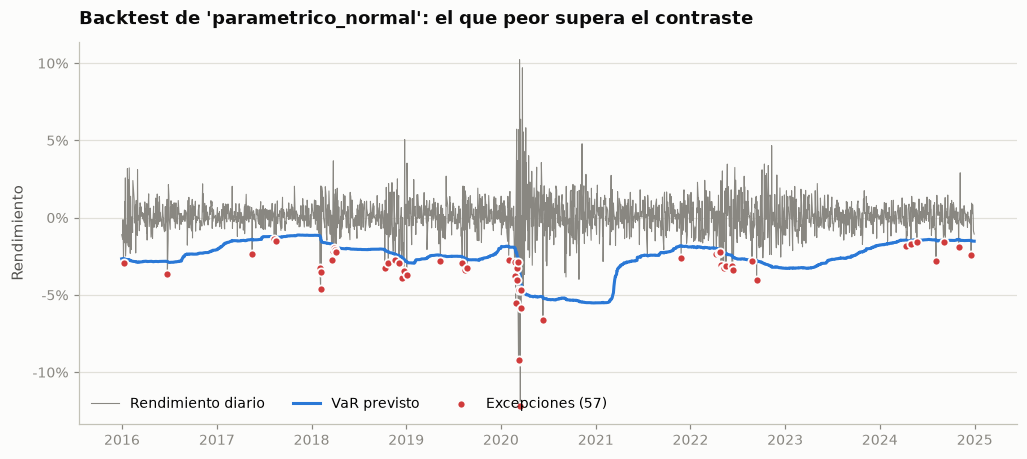

In [19]:
peor = min(contrastes, key=lambda m: contrastes[m].condicional["p_valor"])
detalle_peor = contrastes[peor]
figura, ax = graficos.backtest(cartera, detalle_peor.var, detalle_peor.excepciones)
ax.set_title(f"Backtest de '{peor}': el que peor supera el contraste");

Kupiec        p = 0.198
Independencia p = 0.056
Conjunto      p = 0.070
Zona de Basilea: verde (recargo 0.00)


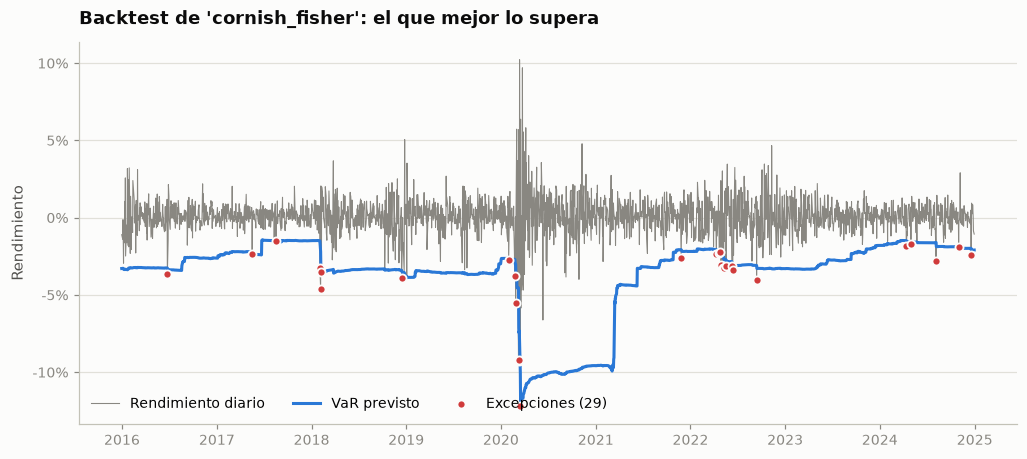

In [20]:
mejor = max(contrastes, key=lambda m: contrastes[m].condicional["p_valor"])
detalle = contrastes[mejor]
figura, ax = graficos.backtest(cartera, detalle.var, detalle.excepciones)
ax.set_title(f"Backtest de '{mejor}': el que mejor lo supera")

print(f"Kupiec        p = {detalle.kupiec['p_valor']:.3f}")
print(f"Independencia p = {detalle.independencia['p_valor']:.3f}")
print(f"Conjunto      p = {detalle.condicional['p_valor']:.3f}")
print(f"Zona de Basilea: {detalle.basilea['zona']} "
      f"(recargo {detalle.basilea['recargo_multiplicador']:.2f})")

## 8. Qué llevarse de aquí

1. **Los rendimientos no son normales**, y el VaR paramétrico normal falla
   precisamente en la cola. La sección 1 lo mide y la 7 lo confirma contando
   excepciones.
2. **La volatilidad cambia de régimen.** Un modelo condicional (EWMA, GARCH) sube el
   VaR el día después de una sesión mala; uno histórico tarda tantos días como
   tenga la ventana.
3. **La dependencia de cola no es un refinamiento académico.** Elegir cópula
   gaussiana en lugar de t cambia el ES al 99 % en una cifra que se ve en la tabla
   de la sección 6.
4. **Contrastar el modelo no es opcional.** Kupiec y Christoffersen responden dos
   preguntas distintas, y un modelo puede pasar el primero y fallar el segundo: el
   número de excepciones cuadra, pero llegan todas juntas.
5. **Pasar el contraste no basta: hay que saber por qué se pasa.** Cornish-Fisher
   es el ejemplo de esta sección. Fuera de su dominio de validez infla el VaR, y
   un VaR inflado produce pocas excepciones y un semáforo verde por el motivo
   equivocado. La cifra que avala un modelo y la que lo delata pueden ser la
   misma.
6. Y una advertencia de método: el VaR dice dónde está el umbral, no lo que hay
   detrás. Por eso el ES, que sí mira dentro de la cola, es la medida que ha
   acabado imponiéndose en la regulación.